# Bike Rental Demand Prediction Using Machine Learning
**Machine Learning Zoomcamp 2026 Midterm Project**  
*Modules 1–6: Problem Definition, EDA, Feature Engineering, Regression Models, Trees & Ensembles, Evaluation & Deployment*

---

## 1. Problem Definition & Context

### 1.1 Business Understanding
Bike sharing systems automate the entire rental and return process across extensive city networks. With hundreds of thousands of bicycles across metropolitan areas, matching supply with demand is a vital operational challenge. For operators like **Capital Bikeshare** in Washington, D.C., anticipating demand prevents:
1. **Empty stations**: Frustrated commuters unable to find an available bike during rush hour.
2. **Full stations**: Users unable to dock their bikes at their destination.
3. **Inefficient logistics**: Excessive fuel and labor costs spent hauling bikes between stations on rebalancing trucks.

### 1.2 Objective
Develop an end-to-end reproducible machine learning regression pipeline predicting total hourly bike rental demand (`cnt`) using historical environmental, calendar, and seasonal features from the UCI Bike Sharing Dataset (`data/hour.csv`).

### 1.3 Critical Modeling Constraints & Target Leakage Prevention
- **Target Variable**: `cnt` (total count of rented bicycles).
- **Strict Leakage Prohibition**: `casual` (rentals by unregistered riders) and `registered` (rentals by registered members) sum to `cnt` ($casual + registered = cnt$). These values are recorded *after* rentals occur and are not available at prediction time. **Using `casual` or `registered` as input features constitutes complete target leakage and is strictly prohibited.**
- **Identifier Exclusion**: `instant` is an arbitrary row index and must be excluded.


In [1]:
import os, sys
sys.path.insert(0, os.path.abspath("."))
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline

from pipeline_utils import (
    FEATURE_COLUMNS,
    TARGET_COLUMN,
    LEAKAGE_COLUMNS,
    IDENTIFIER_COLUMNS,
    BikeFeatureEngineer
)

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Data Loading & Inspection

We load the official UCI Bike Sharing Dataset (`data/hour.csv`), verify its schema, check data types, and confirm zero missing values.


In [2]:
DATA_PATH = "data/hour.csv"
df = pd.read_csv(DATA_PATH)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nColumn Data Types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())


Dataset Shape: 17379 rows, 17 columns

Column Data Types:
instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64

Missing values per column:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0


In [3]:
# Verify the strict leakage identity: casual + registered == cnt
leakage_check = (df['casual'] + df['registered'] == df['cnt']).all()
print(f"Verification of target identity (casual + registered == cnt): {leakage_check}")
if leakage_check:
    print("\nStrict Leakage Check Passed: 'casual' and 'registered' sum exactly to 'cnt'. Both are strictly excluded from input features.")

df.head(3)


Verification of target identity (casual + registered == cnt): True

Strict Leakage Check Passed: 'casual' and 'registered' sum exactly to 'cnt'. Both are strictly excluded from input features.


## 3. Exploratory Data Analysis (EDA)

### 3.1 Target Variable Analysis
The target variable `cnt` represents the hourly bicycle rental count. It has a positive right skew of 1.28, with a median of 142 bikes/hour and a maximum of 977 bikes/hour.


Target cnt Summary Statistics:
count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Skewness: 1.2774
Kurtosis: 1.4172


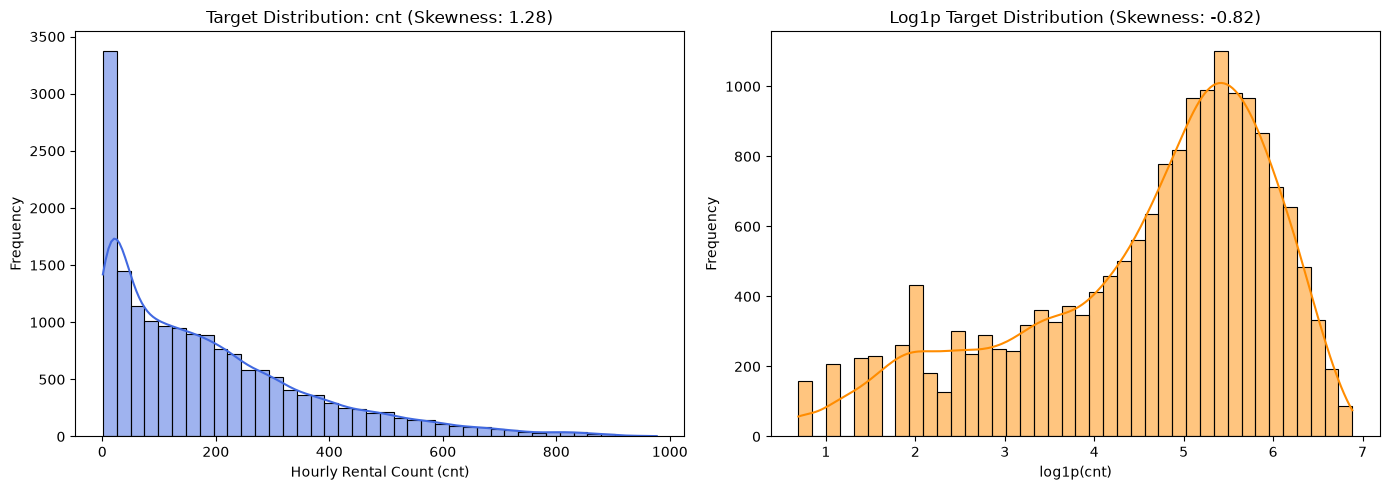

In [4]:
# 3.1 Target Variable Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw distribution
sns.histplot(df['cnt'], kde=True, ax=axes[0], color='royalblue', bins=40)
axes[0].set_title(f"Target Distribution: cnt (Skewness: {df['cnt'].skew():.2f})")
axes[0].set_xlabel("Hourly Rental Count (cnt)")
axes[0].set_ylabel("Frequency")

# Log1p distribution
sns.histplot(np.log1p(df['cnt']), kde=True, ax=axes[1], color='darkorange', bins=40)
axes[1].set_title(f"Log1p Target Distribution (Skewness: {np.log1p(df['cnt']).skew():.2f})")
axes[1].set_xlabel("log1p(cnt)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print("Target cnt Summary Statistics:")
print(df['cnt'].describe())


### 3.2 Hourly Demand Patterns: Working Day vs Weekend / Holiday
Analysis of the hourly profile reveals distinct behaviors:
- **Working Days**: Bimodal commuter peaks at 8:00 AM (average ~360 bikes) and 5:00–6:00 PM (average ~500 bikes).
- **Weekends/Holidays**: Unimodal leisure curve peaking smoothly between 12:00 PM and 4:00 PM (average ~380 bikes).


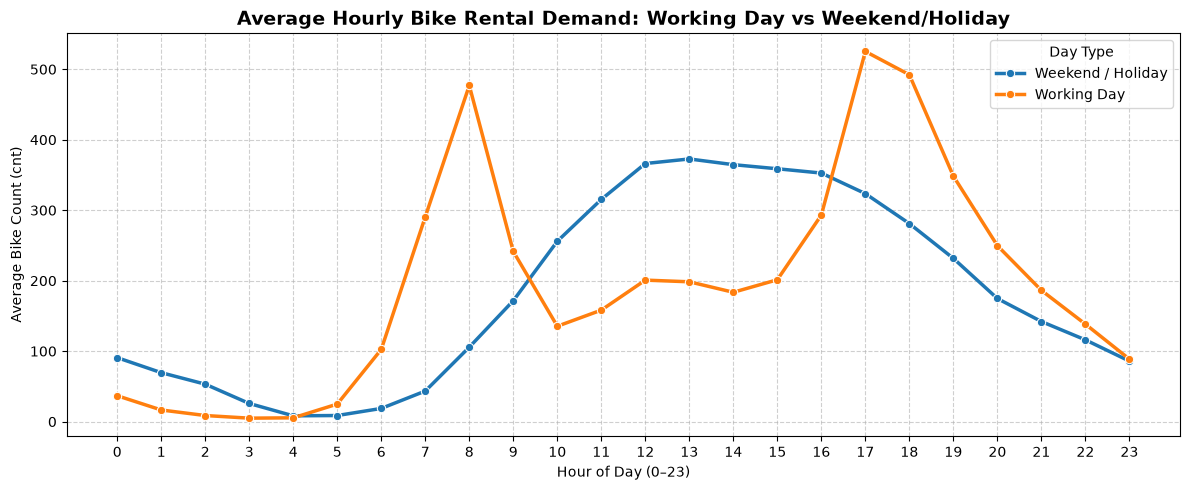

In [5]:
# 3.2 Hourly Demand: Working Day vs Weekend / Holiday
plt.figure(figsize=(12, 5))
hourly_profile = df.groupby(['hr', 'workingday'])['cnt'].mean().reset_index()
hourly_profile['Day Type'] = hourly_profile['workingday'].map({1: 'Working Day', 0: 'Weekend / Holiday'})

sns.lineplot(data=hourly_profile, x='hr', y='cnt', hue='Day Type', marker='o', linewidth=2.5)
plt.title("Average Hourly Bike Rental Demand: Working Day vs Weekend/Holiday", fontsize=14, fontweight='bold')
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Average Bike Count (cnt)")
plt.xticks(range(0, 24))
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


### 3.3 Seasonal & Weather Impact
- **Season**: Fall (Q3) and Summer (Q2) exhibit peak demand, while Spring (Q1) records the lowest usage.
- **Weather Situation**: Clear weather records highest mean demand (~205 bikes/hr), decreasing to ~175 in mist, ~111 in light rain/snow, and ~74 in severe weather.


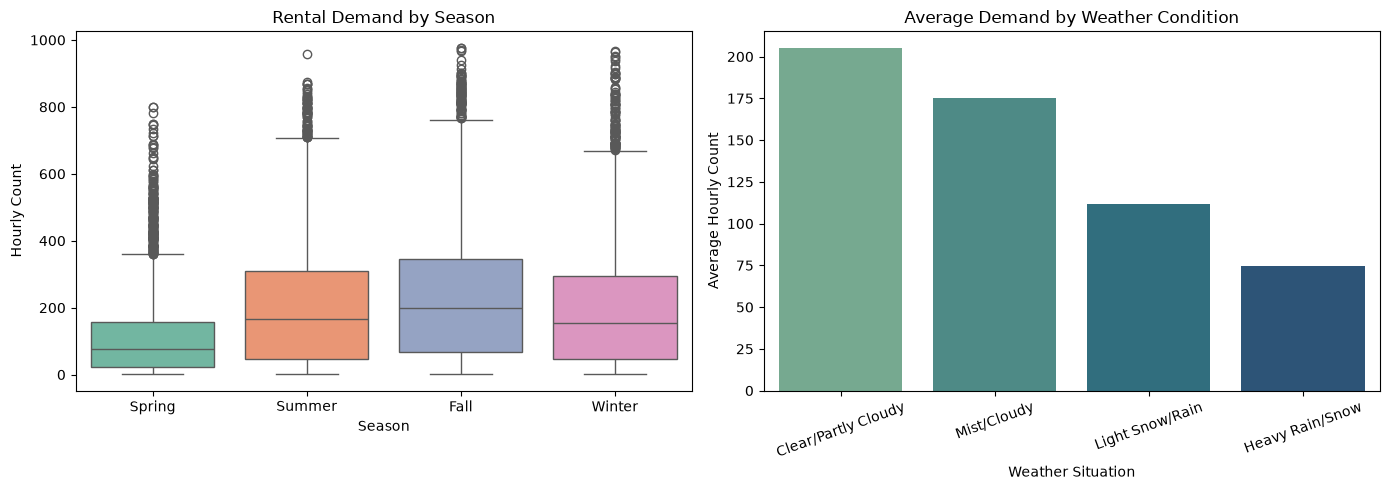

In [6]:
# 3.3 Seasonal and Weather Influences
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

season_labels = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_labels = {1: 'Clear/Partly Cloudy', 2: 'Mist/Cloudy', 3: 'Light Snow/Rain', 4: 'Heavy Rain/Snow'}

df_plot = df.copy()
df_plot['season_name'] = df_plot['season'].map(season_labels)
df_plot['weather_name'] = df_plot['weathersit'].map(weather_labels)

sns.boxplot(data=df_plot, x='season_name', y='cnt', ax=axes[0], palette="Set2")
axes[0].set_title("Rental Demand by Season")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Hourly Count")

sns.barplot(data=df_plot, x='weather_name', y='cnt', ax=axes[1], palette="crest", errorbar=None)
axes[1].set_title("Average Demand by Weather Condition")
axes[1].set_xlabel("Weather Situation")
axes[1].set_ylabel("Average Hourly Count")
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


### 3.4 Feature Correlations
Temperature (`temp`) and feeling temperature (`atemp`) exhibit strong positive correlation with rental count ($r \approx 0.40$), while humidity (`hum`) has a negative correlation ($r \approx -0.32$). Temperature and feeling temperature have near-perfect collinearity ($r = 0.99$).


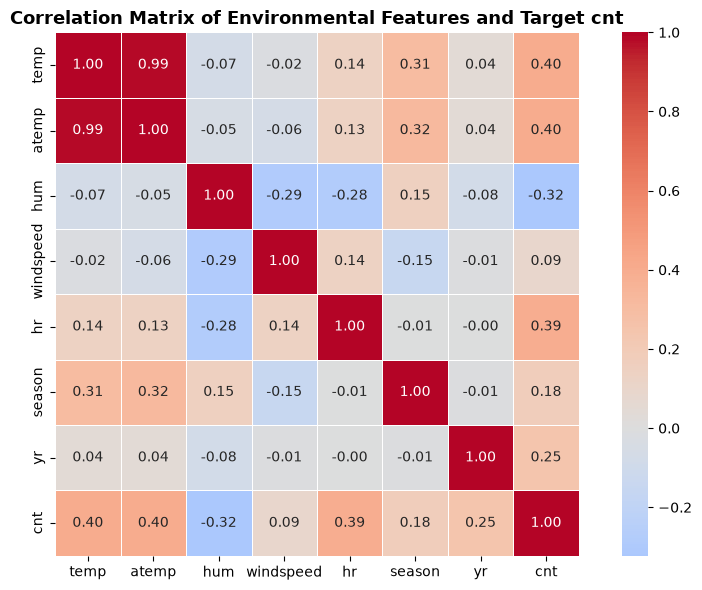

In [7]:
# 3.4 Feature Correlation Heatmap (excluding leakage features)
corr_features = ['temp', 'atemp', 'hum', 'windspeed', 'hr', 'season', 'yr', 'cnt']
corr_matrix = df[corr_features].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Correlation Matrix of Environmental Features and Target cnt", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 4. Feature Engineering

We create domain-informed features:
1. **Cyclical Transforms**: `hr_sin`, `hr_cos` for hour of day, and `mnth_sin`, `mnth_cos` for month of year.
2. **Commute Rush Hour Flag**: Working day commute peaks ($7–9\text{ AM}$, $16–19\text{ PM}$).
3. **Late Night Flag**: Overnight hours ($0–5\text{ AM}$).
4. **Weekend Leisure Flag**: Daytime weekend hours ($10\text{ AM}–4\text{ PM}$).
5. **Weather Comfort Index**: $temp \times (1 - hum)$.
6. **Temperature Differential**: $atemp - temp$.
7. **Adverse Weather Indicator**: Weather situation $\ge 3$.


In [8]:
# Test feature engineering transformer
fe = BikeFeatureEngineer()
engineered_df = fe.transform(df.drop(columns=LEAKAGE_COLUMNS + IDENTIFIER_COLUMNS + ['cnt', 'dteday']))

print(f"Original feature count: {len(FEATURE_COLUMNS)}")
print(f"Engineered feature count: {engineered_df.shape[1]}")
print("\nEngineered Feature Names:")
print(list(engineered_df.columns))
engineered_df.head(3)


Original feature count: 12
Engineered feature count: 22

Engineered Feature Names:
['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'hr_sin', 'hr_cos', 'mnth_sin', 'mnth_cos', 'is_rush_hour', 'is_night', 'is_weekend_leisure', 'temp_hum_interaction', 'temp_diff', 'bad_weather']


## 5. Chronological Train / Validation / Test Splitting

To prevent future lookahead bias, we split strictly by time:
- **Train (70%)**: 12,165 hours (2011-01-01 to 2012-05-27)
- **Validation (15%)**: 2,606 hours (2012-05-27 to 2012-09-12)
- **Test (15%)**: 2,608 hours (2012-09-12 to 2012-12-31)


In [9]:
# Chronological data partition
clean_df = df.drop(columns=LEAKAGE_COLUMNS + IDENTIFIER_COLUMNS).copy()

n = len(clean_df)
n_train = int(n * 0.70)
n_val = int(n * 0.15)

train_df = clean_df.iloc[:n_train].copy()
val_df = clean_df.iloc[n_train:n_train + n_val].copy()
test_df = clean_df.iloc[n_train + n_val:].copy()

X_train = train_df[FEATURE_COLUMNS].copy()
y_train = train_df[TARGET_COLUMN].values

X_val = val_df[FEATURE_COLUMNS].copy()
y_val = val_df[TARGET_COLUMN].values

X_test = test_df[FEATURE_COLUMNS].copy()
y_test = test_df[TARGET_COLUMN].values

print(f"Train set: {len(X_train)} samples ({train_df['dteday'].min()} to {train_df['dteday'].max()})")
print(f"Val set:   {len(X_val)} samples ({val_df['dteday'].min()} to {val_df['dteday'].max()})")
print(f"Test set:  {len(X_test)} samples ({test_df['dteday'].min()} to {test_df['dteday'].max()})")


Train set: 12165 samples (2011-01-01 to 2012-05-27)
Val set:   2606 samples (2012-05-27 to 2012-09-12)
Test set:  2608 samples (2012-09-12 to 2012-12-31)


## 6. Model Training & Validation Comparison

We evaluate 7 models on the validation set using **RMSE**, **MAE**, and **$R^2$**:
1. **Baseline**: Historical train mean
2. **Linear Regression (OLS)**
3. **Ridge Regression**
4. **Decision Tree Regressor**
5. **Random Forest Regressor**
6. **Gradient Boosting Regressor (GBR)**
7. **Histogram Gradient Boosting (HistGradientBoosting)**


In [10]:
# Candidate Model Evaluation on Validation Set
X_train_fe = fe.transform(X_train)
X_val_fe = fe.transform(X_val)

def score_preds(y_true, y_pred, name):
    y_pred_clipped = np.clip(y_pred, 0, None)
    return {
        'Model': name,
        'RMSE': round(float(np.sqrt(mean_squared_error(y_true, y_pred_clipped))), 2),
        'MAE': round(float(mean_absolute_error(y_true, y_pred_clipped)), 2),
        'R2': round(float(r2_score(y_true, y_pred_clipped)), 4)
    }

results = []
# 1. Baseline
results.append(score_preds(y_val, np.full_like(y_val, np.mean(y_train)), "Baseline (Train Mean)"))

# 2. Linear Regression
lr = LinearRegression().fit(X_train_fe, y_train)
results.append(score_preds(y_val, lr.predict(X_val_fe), "Linear Regression (OLS)"))

# 3. Ridge Regression
ridge = Ridge(alpha=10.0).fit(X_train_fe, y_train)
results.append(score_preds(y_val, ridge.predict(X_val_fe), "Ridge Regression"))

# 4. Decision Tree
dt = DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=42).fit(X_train_fe, y_train)
results.append(score_preds(y_val, dt.predict(X_val_fe), "Decision Tree"))

# 5. Random Forest
rf = RandomForestRegressor(n_estimators=150, max_depth=16, min_samples_leaf=4, random_state=42, n_jobs=2).fit(X_train_fe, y_train)
results.append(score_preds(y_val, rf.predict(X_val_fe), "Random Forest"))

# 6. Gradient Boosting (GBR)
gbr = GradientBoostingRegressor(n_estimators=150, max_depth=5, learning_rate=0.08, random_state=42).fit(X_train_fe, y_train)
results.append(score_preds(y_val, gbr.predict(X_val_fe), "Gradient Boosting (GBR)"))

# 7. HistGradientBoosting (tuned)
hgb = HistGradientBoostingRegressor(learning_rate=0.08, max_depth=6, l2_regularization=0.1, max_iter=200, random_state=42).fit(X_train_fe, y_train)
results.append(score_preds(y_val, hgb.predict(X_val_fe), "HistGradientBoosting"))

results_df = pd.DataFrame(results).sort_values(by='RMSE')
print(results_df.to_string(index=False))


                  Model   RMSE    MAE      R2
   HistGradientBoosting  60.12  40.24  0.9275
Gradient Boosting (GBR)  67.01  45.75  0.9099
          Random Forest  69.93  46.30  0.9019
          Decision Tree  74.77  49.65  0.8878
Linear Regression (OLS) 136.04 108.69  0.6286
       Ridge Regression 136.69 109.18  0.6250
  Baseline (Train Mean) 253.93 194.08 -0.2939


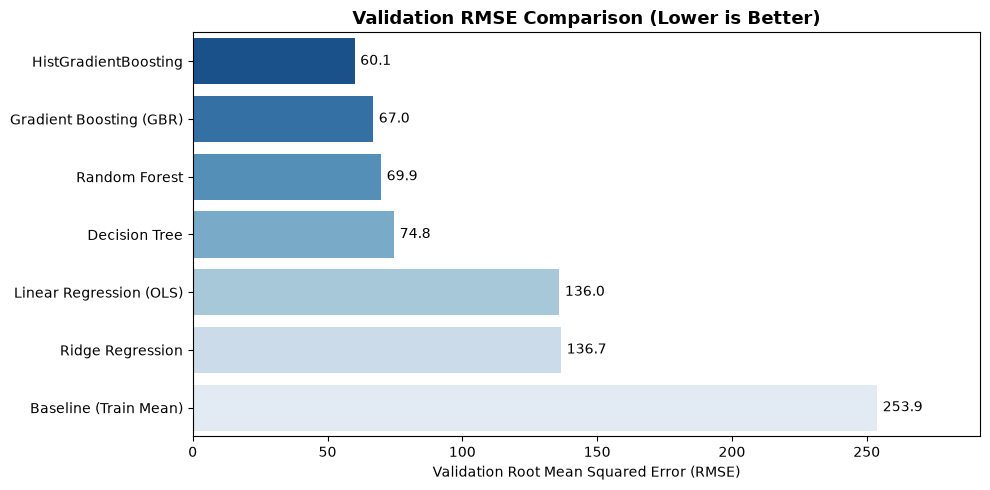

In [11]:
# Visualize Validation Comparison
plt.figure(figsize=(10, 5))
barplot = sns.barplot(data=results_df, x='RMSE', y='Model', palette='Blues_r')
plt.title("Validation RMSE Comparison (Lower is Better)", fontsize=13, fontweight='bold')
plt.xlabel("Validation Root Mean Squared Error (RMSE)")
plt.ylabel("")

for p in barplot.patches:
    width = p.get_width()
    barplot.annotate(f"{width:.1f}", (width + 2, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center', fontsize=10, color='black')

plt.xlim(0, max(results_df['RMSE']) * 1.15)
plt.tight_layout()
plt.show()


## 7. Champion Model Selection & Final Test Evaluation

**HistGradientBoostingRegressor** is selected as the champion model with validation RMSE = 60.12 and $R^2 = 0.9275$.

We retrain the entire pipeline on the combined **Train + Validation** set (14,771 hours) and evaluate on the unseen **Test Set** strictly **ONCE**.


In [12]:
# Retrain champion pipeline on combined Train + Validation data
train_val_df = pd.concat([train_df, val_df], axis=0)
X_train_val = train_val_df[FEATURE_COLUMNS].copy()
y_train_val = train_val_df[TARGET_COLUMN].values

champion_pipeline = Pipeline([
    ('feature_engineer', BikeFeatureEngineer()),
    ('regressor', HistGradientBoostingRegressor(
        learning_rate=0.08,
        max_depth=6,
        l2_regularization=0.1,
        max_iter=200,
        random_state=42
    ))
])
champion_pipeline.fit(X_train_val, y_train_val)

# Single Final Test Evaluation
test_preds = np.clip(champion_pipeline.predict(test_df[FEATURE_COLUMNS]), 0, None)
test_rmse = round(float(np.sqrt(mean_squared_error(y_test, test_preds))), 2)
test_mae = round(float(mean_absolute_error(y_test, test_preds)), 2)
test_r2 = round(float(r2_score(y_test, test_preds)), 4)

print("=== FINAL TEST SET EVALUATION (Held-out Test Set) ===")
print("Model: HistGradientBoostingRegressor (Trained on Train + Validation)")
print(f"Test RMSE: {test_rmse}")
print(f"Test MAE:  {test_mae}")
print(f"Test R2:   {test_r2}")


=== FINAL TEST SET EVALUATION (Held-out Test Set) ===
Model: HistGradientBoostingRegressor (Trained on Train + Validation)
Test RMSE: 68.56
Test MAE:  45.14
Test R2:   0.8984


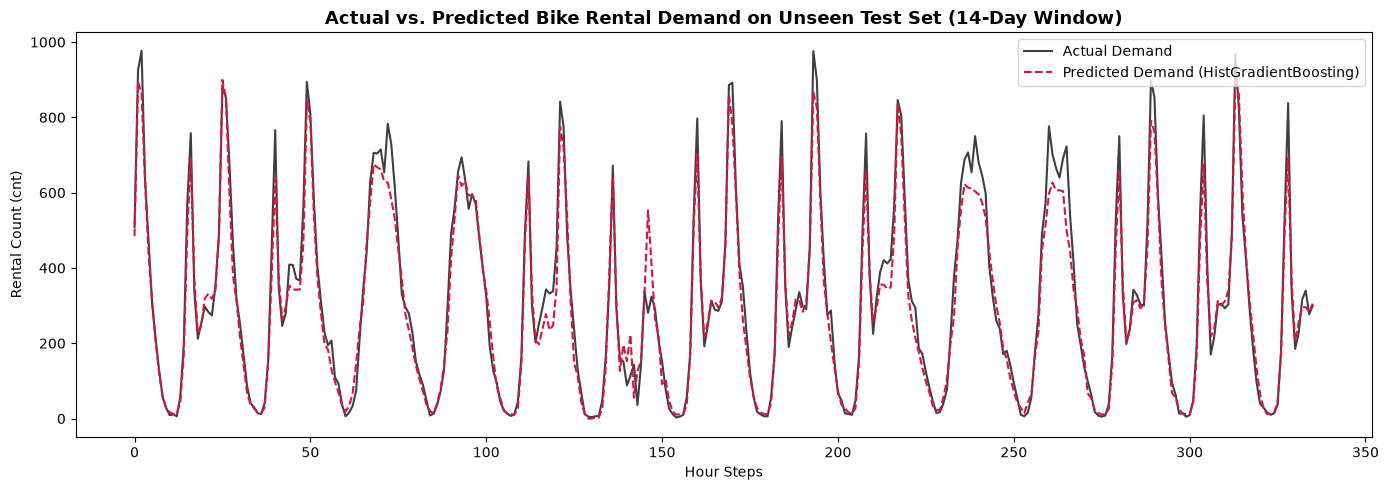

In [13]:
# Plot Actual vs Predicted on Test Set (14-day sample)
plt.figure(figsize=(14, 5))
sample_window = 24 * 14
plt.plot(y_test[:sample_window], label='Actual Demand', color='black', alpha=0.75, linewidth=1.5)
plt.plot(test_preds[:sample_window], label='Predicted Demand (HistGradientBoosting)', color='crimson', linestyle='--', linewidth=1.5)
plt.title("Actual vs. Predicted Bike Rental Demand on Unseen Test Set (14-Day Window)", fontsize=13, fontweight='bold')
plt.xlabel("Hour Steps")
plt.ylabel("Rental Count (cnt)")
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


## 8. Pipeline Serialization & Inference Verification

We serialize the complete Pipeline using Joblib to `models/bike_rental_model.joblib`. We verify inference by sending a test observation and confirming prediction accuracy.


In [14]:
# Verify Saved Pipeline and Real-time Inference
import joblib

model_path = "models/bike_rental_model.joblib"
loaded_pipeline = joblib.load(model_path)
print(f"Pipeline successfully loaded from: {model_path}\n")

test_request = {
    "season": 3,
    "yr": 1,
    "mnth": 7,
    "hr": 17,
    "holiday": 0,
    "weekday": 3,
    "workingday": 1,
    "weathersit": 1,
    "temp": 0.82,
    "atemp": 0.7879,
    "hum": 0.44,
    "windspeed": 0.2239
}

test_df = pd.DataFrame([test_request])
prediction = float(np.clip(loaded_pipeline.predict(test_df)[0], 0, None))
print(f"Test Request Input:\n{test_request}\n")
print(f"-> Predicted Hourly Bike Rental Demand: {prediction:.2f} bikes (Rounded: {int(round(prediction))})")


Pipeline successfully loaded from: models/bike_rental_model.joblib

Test Request Input:
{
  'season': 3, 'yr': 1, 'mnth': 7, 'hr': 17, 'holiday': 0, 'weekday': 3,
  'workingday': 1, 'weathersit': 1, 'temp': 0.82, 'atemp': 0.7879, 'hum': 0.44, 'windspeed': 0.2239
}

-> Predicted Hourly Bike Rental Demand: 774.94 bikes (Rounded: 775)
